In [2]:
!kaggle datasets download -d clmentbisaillon/fake-and-real-news-dataset --unzip -p /fake-news-detector/data

import pandas as pd
fake = pd.read_csv("/fake-news-detector/data/Fake.csv")
true = pd.read_csv("/fake-news-detector/data/True.csv")
print(fake.shape, true.shape)

Dataset URL: https://www.kaggle.com/datasets/clmentbisaillon/fake-and-real-news-dataset
License(s): CC-BY-NC-SA-4.0




  0%|          | 0.00/41.0M [00:00<?, ?B/s]
  2%|▏         | 1.00M/41.0M [00:10<06:48, 103kB/s]
  5%|▍         | 2.00M/41.0M [00:14<04:24, 155kB/s]
  7%|▋         | 3.00M/41.0M [00:17<03:16, 203kB/s]
 10%|▉         | 4.00M/41.0M [00:20<02:30, 258kB/s]
 12%|█▏        | 5.00M/41.0M [00:22<02:01, 310kB/s]
 15%|█▍        | 6.00M/41.0M [00:25<01:53, 324kB/s]
 17%|█▋        | 7.00M/41.0M [00:27<01:41, 350kB/s]
 20%|█▉        | 8.00M/41.0M [00:30<01:33, 368kB/s]
 22%|██▏       | 9.00M/41.0M [00:33<01:30, 373kB/s]
 24%|██▍       | 10.0M/41.0M [00:35<01:25, 379kB/s]
 27%|██▋       | 11.0M/41.0M [00:39<01:27, 358kB/s]
 29%|██▉       | 12.0M/41.0M [00:43<01:37, 311kB/s]
 32%|███▏      | 13.0M/41.0M [00:46<01:32, 318kB/s]
 34%|███▍      | 14.0M/41.0M [00:48<01:14, 378kB/s]
 37%|███▋      | 15.0M/41.0M [00:48<00:56, 479kB/s]
 39%|███▉      | 16.0M/41.0M [00:49<00:44, 585kB/s]
 41%|████▏     | 17.0M/41.0M [00:50<00:33, 759kB/s]
 44%|████▍     | 18.0M/41.0M [00:50<00:24, 1.00MB/s]
 46%|████▋     | 1

(23481, 4) (21417, 4)


In [3]:
true.head()

,title,text,subject,date
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017"
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017"
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017"
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017"
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017"


In [4]:
fake.head()

,title,text,subject,date
0,Donald Trump Sends Out Embarrassing New Year’...,Donald Trump just couldn t wish all Americans ...,News,"December 31, 2017"
1,Drunk Bragging Trump Staffer Started Russian ...,House Intelligence Committee Chairman Devin Nu...,News,"December 31, 2017"
2,Sheriff David Clarke Becomes An Internet Joke...,"On Friday, it was revealed that former Milwauk...",News,"December 30, 2017"
3,Trump Is So Obsessed He Even Has Obama’s Name...,"On Christmas day, Donald Trump announced that ...",News,"December 29, 2017"
4,Pope Francis Just Called Out Donald Trump Dur...,Pope Francis used his annual Christmas Day mes...,News,"December 25, 2017"


In [5]:
fake['fake_or_true'] = "fake"

In [6]:
fake.shape

(23481, 5)

In [7]:
true['fake_or_true'] = "true"

In [8]:
true.shape

(21417, 5)

In [9]:
total_df = pd.concat([true, fake], axis="rows")

In [10]:
total_df.shape

(44898, 5)

In [11]:
total_df['fake_or_true'].value_counts()

fake_or_true
fake    23481
true    21417
Name: count, dtype: int64

In [14]:
import os
total_df.to_csv(r"C:\Users\user\Documents\AgenticAI\fake-news-detector\fake-news-detector\data\fake_new_detection.csv", index=False)

NameError: name 'total_df' is not defined

In [15]:
import pandas as pd
import numpy as np

In [16]:
df = pd.read_csv(r"C:\Users\user\Documents\AgenticAI\fake-news-detector\fake-news-detector\data\fake_new_detection.csv")

In [17]:
df.head()

,title,text,subject,date,fake_or_true
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",true
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",true
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",true
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",true
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",true


In [18]:
FAKE = 1
TRUE = 0
import re

REUTERS_PREFIX = re.compile(r"^\s*[A-Z][A-Za-z .,/'-]{0,60}\(Reuters\)\s*[-–—]\s*")
URL_PATTERN = re.compile(r"https?://\S+|www\.\S+")
TWITTER_HANDLE = re.compile(r"@\w+")
PIC_LINK = re.compile(r"pic\.twitter\.com/\S+")
WHITESPACE = re.compile(r"\s+")

In [19]:
df.iloc[0]['title']

'As U.S. budget fight looms, Republicans flip their fiscal script'

In [20]:
df.iloc[0]['text']

'WASHINGTON (Reuters) - The head of a conservative Republican faction in the U.S. Congress, who voted this month for a huge expansion of the national debt to pay for tax cuts, called himself a “fiscal conservative” on Sunday and urged budget restraint in 2018. In keeping with a sharp pivot under way among Republicans, U.S. Representative Mark Meadows, speaking on CBS’ “Face the Nation,” drew a hard line on federal spending, which lawmakers are bracing to do battle over in January. When they return from the holidays on Wednesday, lawmakers will begin trying to pass a federal budget in a fight likely to be linked to other issues, such as immigration policy, even as the November congressional election campaigns approach in which Republicans will seek to keep control of Congress. President Donald Trump and his Republicans want a big budget increase in military spending, while Democrats also want proportional increases for non-defense “discretionary” spending on programs that support educat

In [21]:
def clean_text(text: str) -> str:
    if not isinstance(text, str):
        return "" 
    text = REUTERS_PREFIX.sub("", text)
    text = URL_PATTERN.sub(" ", text)
    text = PIC_LINK.sub(" ", text) 
    text = TWITTER_HANDLE.sub(" ", text)
    text = text.replace("(Reuters)", " ").replace("Reuters", " ")
    text = text.lower()
    text = WHITESPACE.sub(" ", text).strip()
    return text

In [22]:
df.isna().sum()

title           0
text            0
subject         0
date            0
fake_or_true    0
dtype: int64

In [23]:
df['content'] = (df['title'] + ". " + df['text']).map(clean_text)
df_20 = df[df['content'].str.len() >= 20]
df_20

,title,text,subject,date,fake_or_true,content
0,"As U.S. budget fight looms, Republicans flip t...",WASHINGTON (Reuters) - The head of a conservat...,politicsNews,"December 31, 2017",true,"as u.s. budget fight looms, republicans flip t..."
1,U.S. military to accept transgender recruits o...,WASHINGTON (Reuters) - Transgender people will...,politicsNews,"December 29, 2017",true,u.s. military to accept transgender recruits o...
2,Senior U.S. Republican senator: 'Let Mr. Muell...,WASHINGTON (Reuters) - The special counsel inv...,politicsNews,"December 31, 2017",true,senior u.s. republican senator: 'let mr. muell...
3,FBI Russia probe helped by Australian diplomat...,WASHINGTON (Reuters) - Trump campaign adviser ...,politicsNews,"December 30, 2017",true,fbi russia probe helped by australian diplomat...
4,Trump wants Postal Service to charge 'much mor...,SEATTLE/WASHINGTON (Reuters) - President Donal...,politicsNews,"December 29, 2017",true,trump wants postal service to charge 'much mor...
...,...,...,...,...,...,...
44893,McPain: John McCain Furious That Iran Treated ...,21st Century Wire says As 21WIRE reported earl...,Middle-east,"January 16, 2016",fake,mcpain: john mccain furious that iran treated ...
44894,JUSTICE? Yahoo Settles E-mail Privacy Class-ac...,21st Century Wire says It s a familiar theme. ...,Middle-east,"January 16, 2016",fake,justice? yahoo settles e-mail privacy class-ac...
44895,Sunnistan: US and Allied ‘Safe Zone’ Plan to T...,Patrick Henningsen 21st Century WireRemember ...,Middle-east,"January 15, 2016",fake,sunnistan: us and allied ‘safe zone’ plan to t...
44896,How to Blow $700 Million: Al Jazeera America F...,21st Century Wire says Al Jazeera America will...,Middle-east,"January 14, 2016",fake,how to blow $700 million: al jazeera america f...


In [24]:
len(df_20.iloc[0]['content'])

4711

In [25]:
def prepare(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df['title'] = df['title'].fillna("")
    df["text"] = df['text'].astype(str).map(lambda t: REUTERS_PREFIX.sub("", t))
    df['content'] = (df['title'] + ". " + df['text']).map(clean_text)

    before = len(df)
    df = df[df['content'].str.len() >= 20]
    df = df.drop_duplicates(subset="content")
    print(f"Rows: {before} -> {len(df)} after removing empty rows and duplicate rows")

    return df[["content", "fake_or_true"]].reset_index(drop=True)

df = prepare(df)

Rows: 44898 -> 39095 after removing empty rows and duplicate rows


In [26]:
df.head()

,content,fake_or_true
0,"as u.s. budget fight looms, republicans flip t...",true
1,u.s. military to accept transgender recruits o...,true
2,senior u.s. republican senator: 'let mr. muell...,true
3,fbi russia probe helped by australian diplomat...,true
4,trump wants postal service to charge 'much mor...,true


In [27]:
columns = df.columns.to_list()
columns[1] = "label"
columns

['content', 'label']

In [28]:
df.columns = columns

In [29]:
df.head()

,content,label
0,"as u.s. budget fight looms, republicans flip t...",true
1,u.s. military to accept transgender recruits o...,true
2,senior u.s. republican senator: 'let mr. muell...,true
3,fbi russia probe helped by australian diplomat...,true
4,trump wants postal service to charge 'much mor...,true


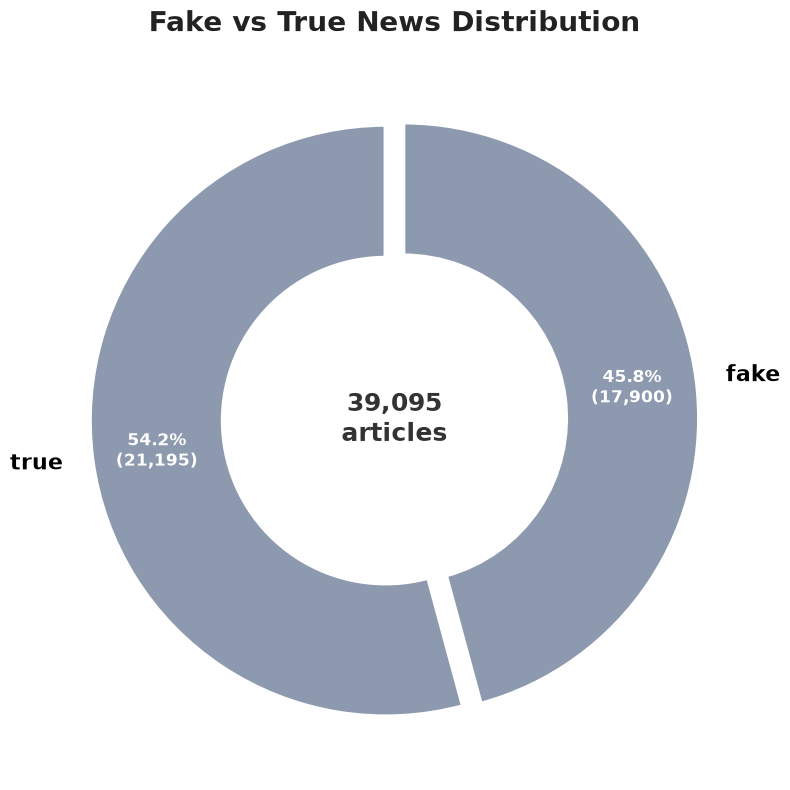

In [30]:
import matplotlib.pyplot as plt

counts = df['label'].value_counts()

# If your labels are 0/1, give them readable names (check which number is Fake in your data)
counts.index = counts.index.map(lambda x: {0: 'Fake', 1: 'True'}.get(x, x))

colors = {'Fake': '#E63946', 'True': '#2A9D8F'}
slice_colors = [colors.get(str(i), '#8D99AE') for i in counts.index]

fig, ax = plt.subplots(figsize=(8, 8), facecolor='white')

wedges, texts, autotexts = ax.pie(
    counts,
    labels=counts.index,
    colors=slice_colors,
    autopct=lambda p: f'{p:.1f}%\n({int(round(p * counts.sum() / 100)):,})',
    startangle=90,
    explode=[0.03] * len(counts),
    pctdistance=0.78,
    wedgeprops=dict(width=0.45, edgecolor='white', linewidth=3),
    textprops=dict(fontsize=14),
)

# Style the labels and percentages
for t in texts:
    t.set_fontsize(16)
    t.set_fontweight('bold')
for t in autotexts:
    t.set_color('white')
    t.set_fontsize(12)
    t.set_fontweight('bold')

# Total in the middle of the donut
ax.text(0, 0, f'{counts.sum():,}\narticles', ha='center', va='center',
        fontsize=18, fontweight='bold', color='#333333')

ax.set_title('Fake vs True News Distribution', fontsize=20, fontweight='bold',
             pad=20, color='#222222')
ax.axis('equal')

plt.tight_layout()
plt.savefig(r'C:\Users\user\Documents\AgenticAI\fake-news-detector\fake-news-detector\data\label_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

In [31]:
df.to_csv(r"C:\Users\user\Documents\AgenticAI\fake-news-detector\fake-news-detector\data\fake_news_detector_cleaned.csv", index=False)

In [32]:
from sklearn.model_selection import train_test_split

In [33]:
def split(df: pd.DataFrame):
    train, temp = train_test_split(df, test_size=0.3, stratify=df['label'], random_state=42)
    val, test = train_test_split(temp, test_size=0.5, stratify=temp["label"], random_state=42)

    return train, val, test

In [34]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
try:
    import mlflow
    import mlflow.sklearn

    MLFLOW_AVAILABLE = TRUE
except ImportError:
    MLFLOW_AVAILABLE = False

model_dir = r"C:\Users\user\Documents\AgenticAI\fake-news-detector\fake-news-detector\models"

c:\Users\user\Documents\AgenticAI\fake-news-detector\fake-news-detector\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


```python
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
Pipeline(
    [    
        ("scaler", StandardScaler())
        ("log_reg", LogisticRegresion()),
    ]
)
```

In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer

corpus = [
    "this is the first document",
    "this document is the second document",
    "and this is the third one",
]

vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(corpus)

print(vectorizer.get_feature_names_out())
print(X.toarray())

['and' 'document' 'first' 'is' 'one' 'second' 'the' 'third' 'this']
[[0.         0.46941728 0.61722732 0.3645444  0.         0.
  0.3645444  0.         0.3645444 ]
 [0.         0.7284449  0.         0.28285122 0.         0.47890875
  0.28285122 0.         0.28285122]
 [0.49711994 0.         0.         0.29360705 0.49711994 0.
  0.29360705 0.49711994 0.29360705]]


In [36]:
text_corpus = " ".join(corpus)
text_corpus = text_corpus.split()
text_corpus

['this',
 'is',
 'the',
 'first',
 'document',
 'this',
 'document',
 'is',
 'the',
 'second',
 'document',
 'and',
 'this',
 'is',
 'the',
 'third',
 'one']

In [37]:
output = {}

for word in text_corpus:
    if word in output:
        output[word] += 1
    else:
        output[word] = 1

output

{'this': 3,
 'is': 3,
 'the': 3,
 'first': 1,
 'document': 3,
 'second': 1,
 'and': 1,
 'third': 1,
 'one': 1}

In [38]:
print(vectorizer.get_feature_names_out())
X.toarray()[0]

['and' 'document' 'first' 'is' 'one' 'second' 'the' 'third' 'this']


array([0.        , 0.46941728, 0.61722732, 0.3645444 , 0.        ,
       0.        , 0.3645444 , 0.        , 0.3645444 ])

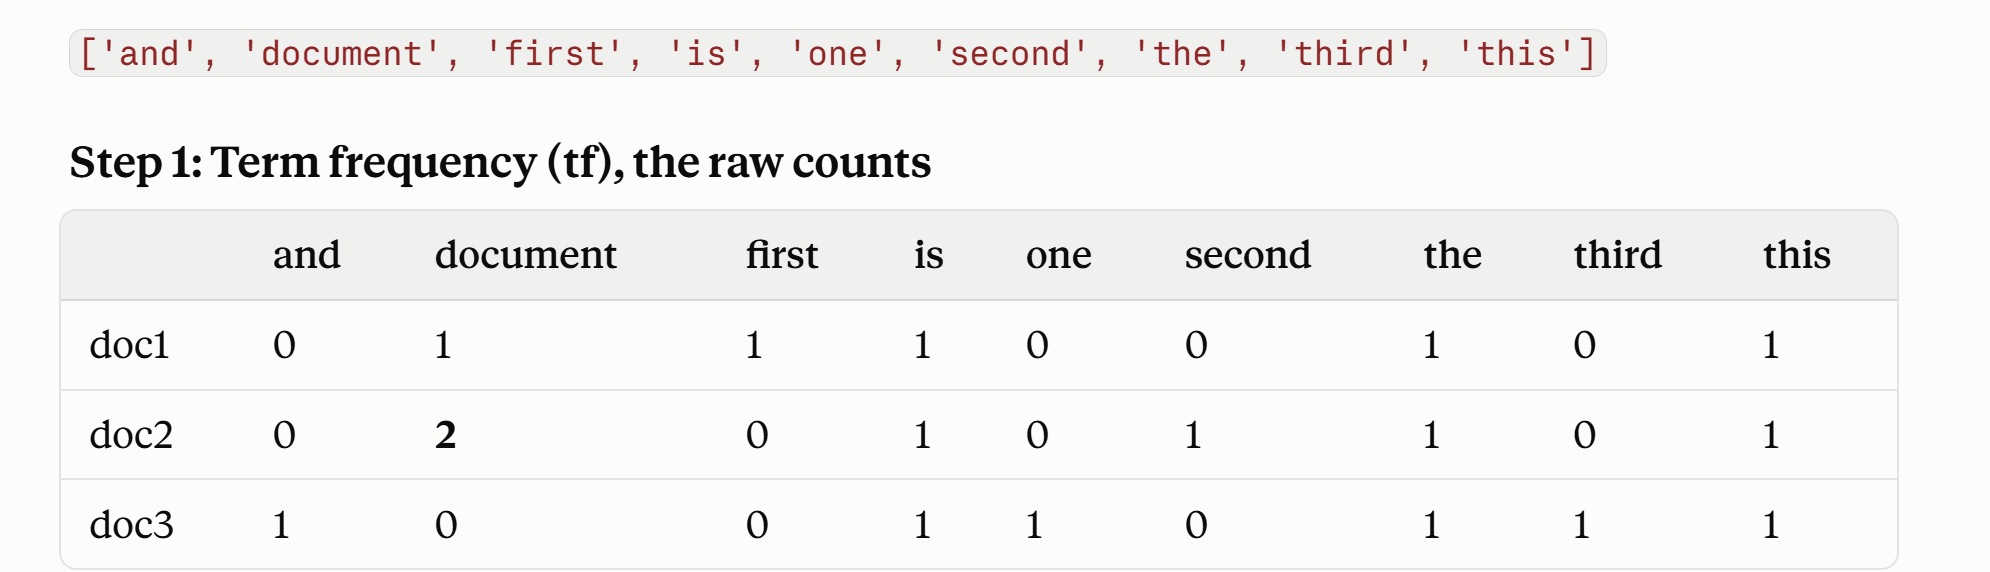

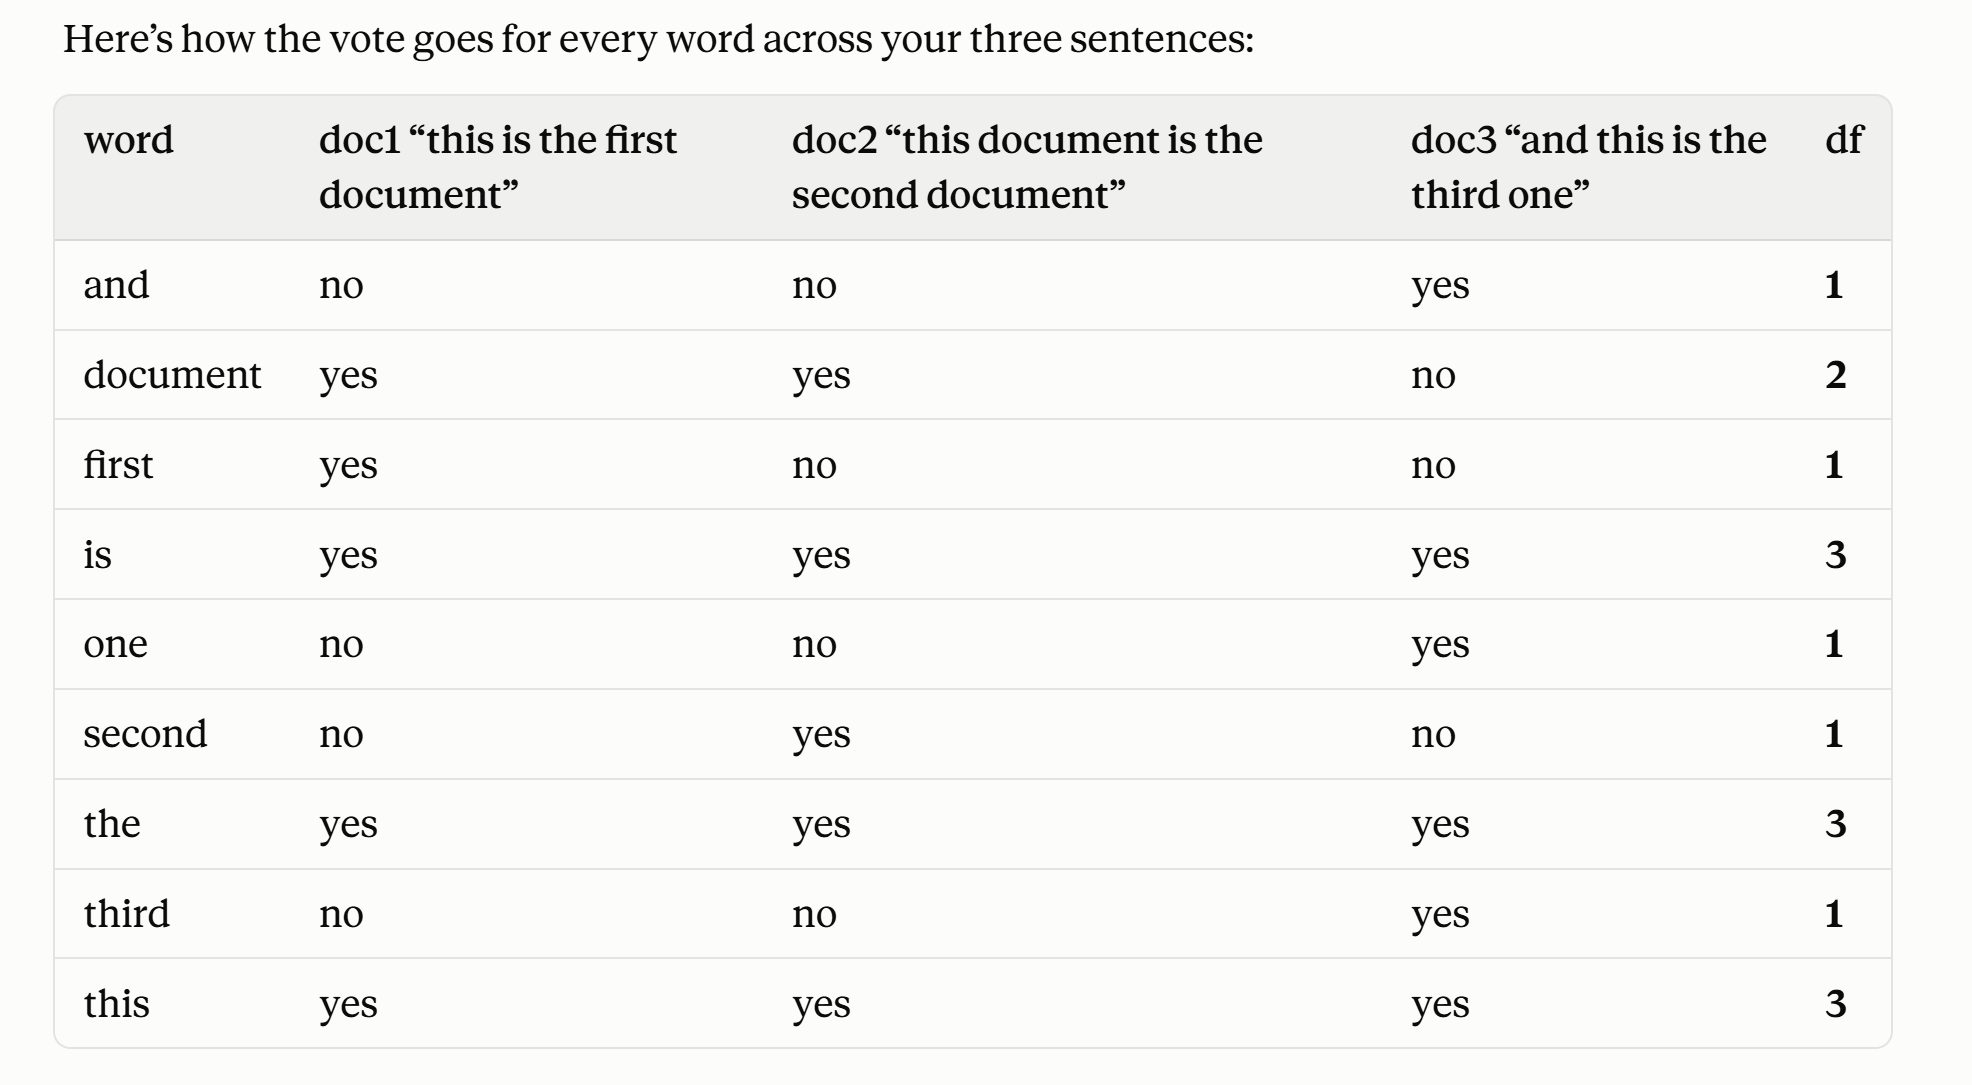

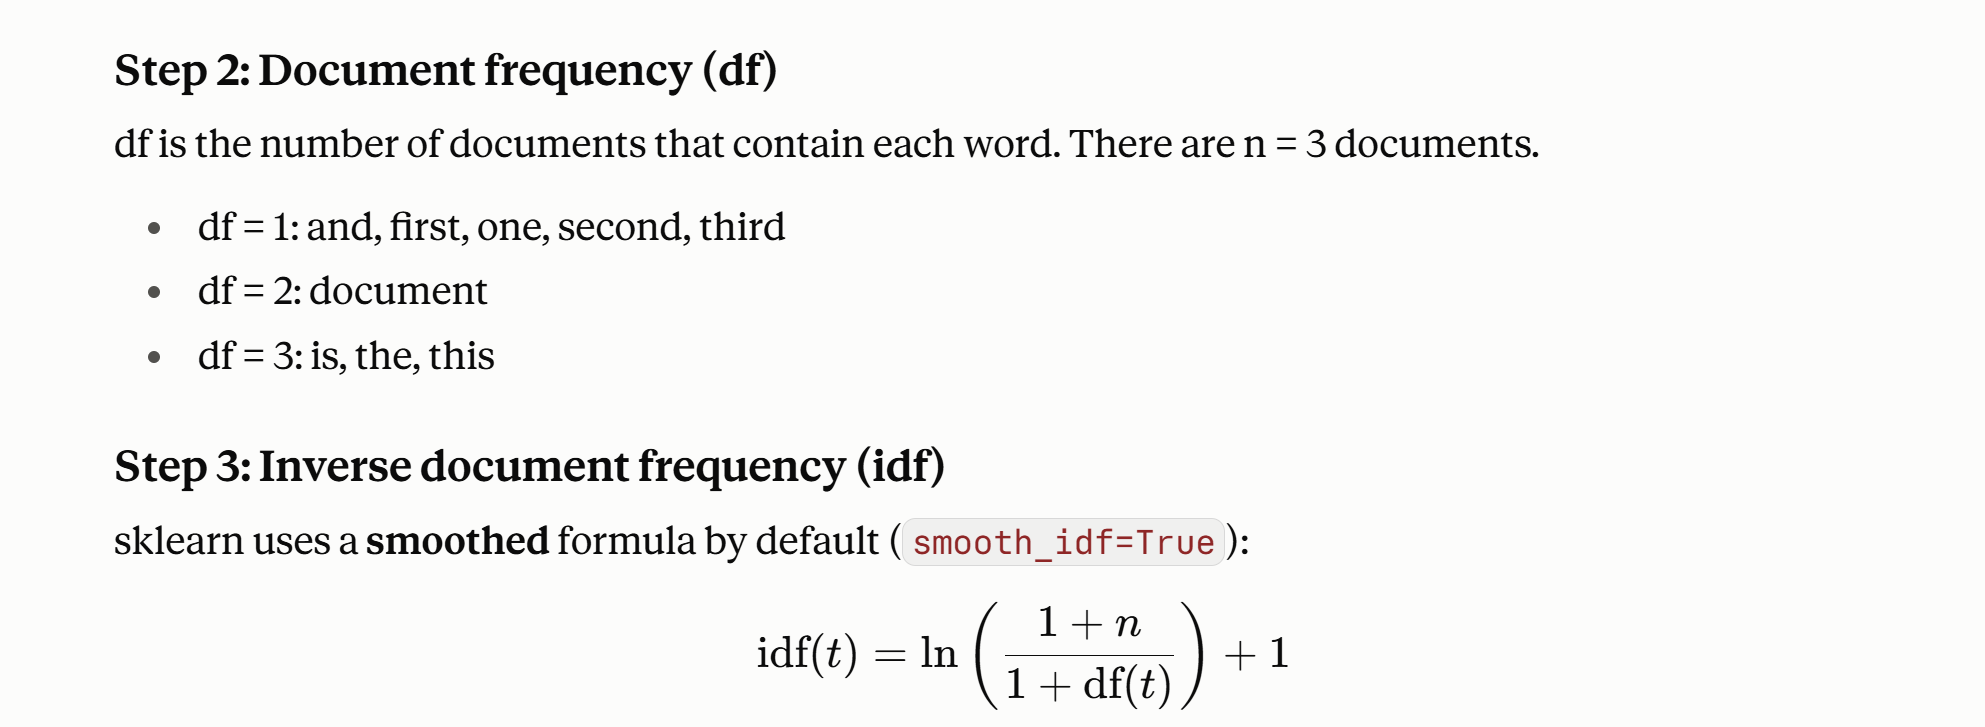

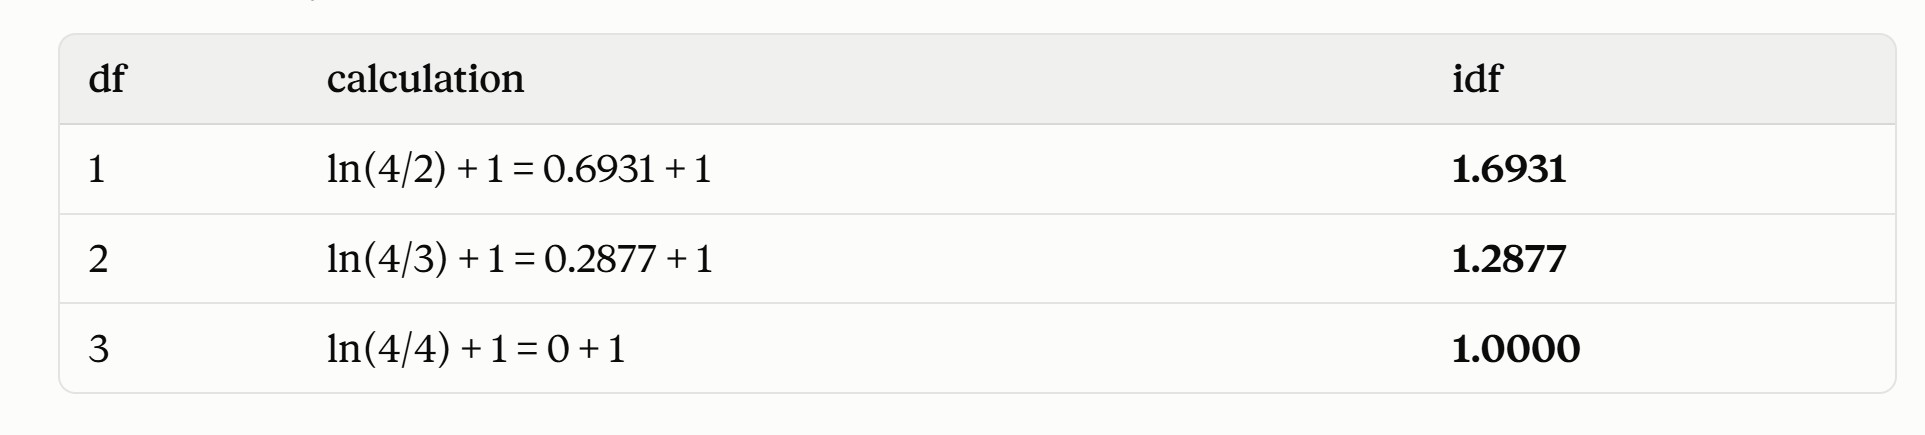

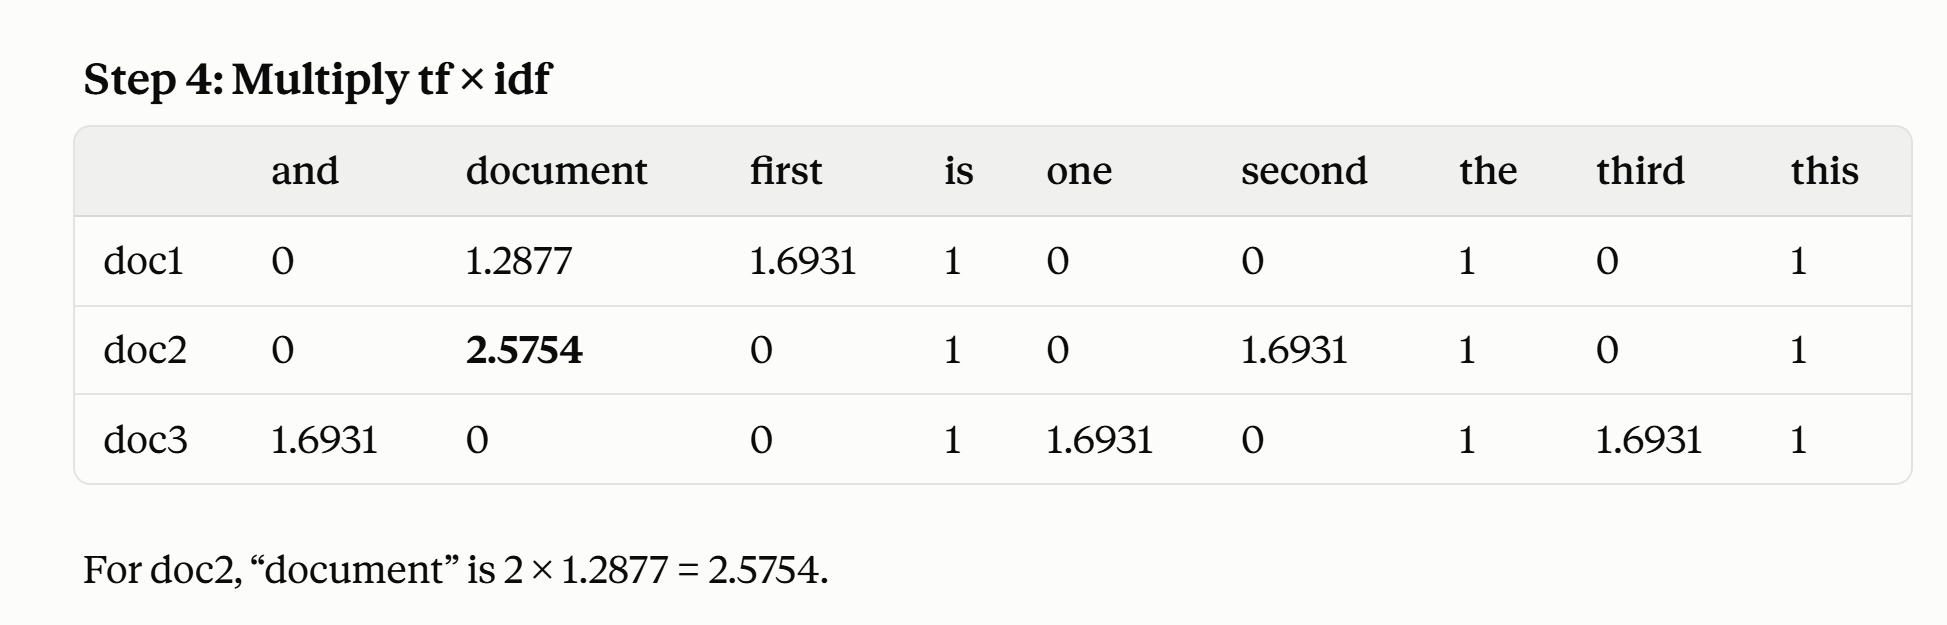

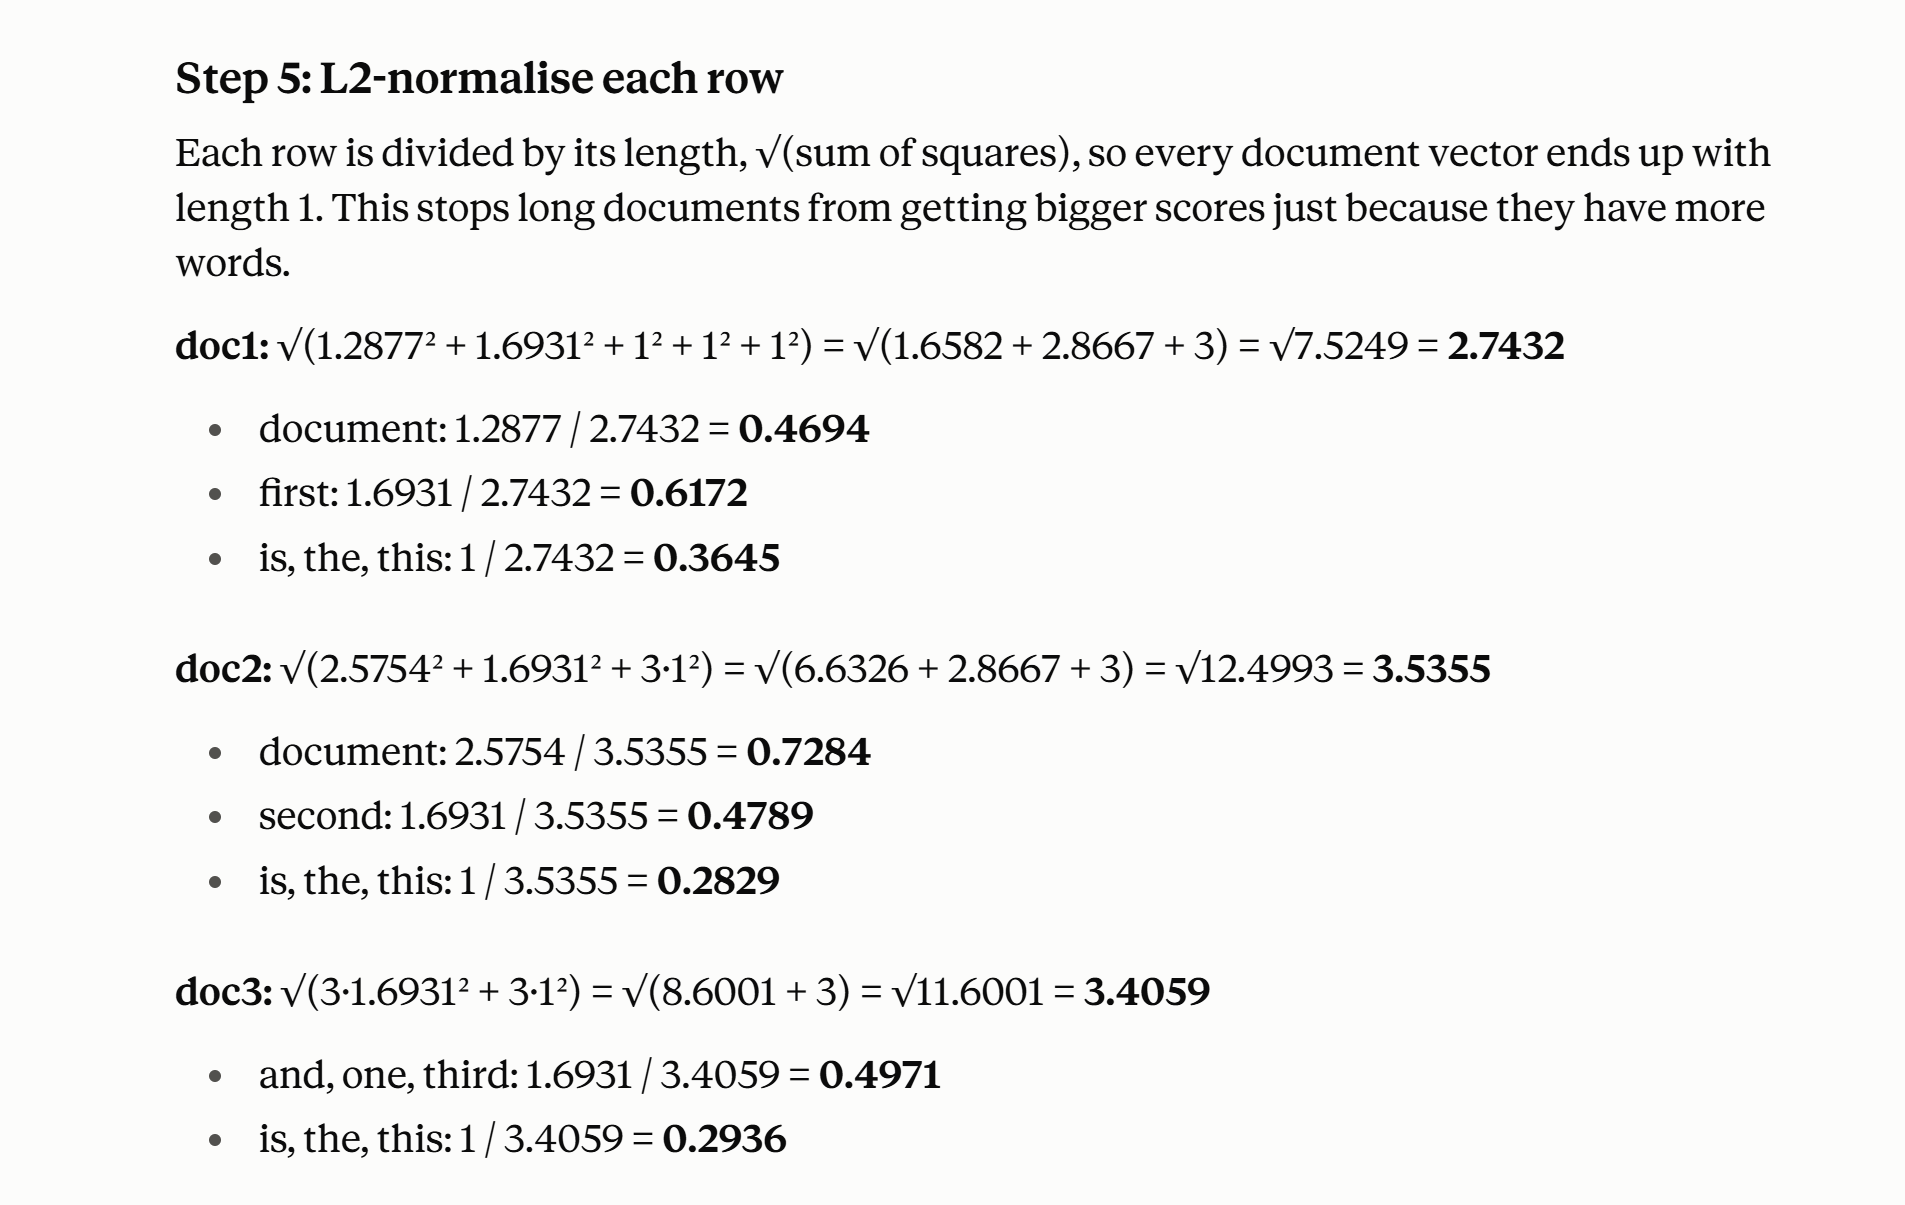

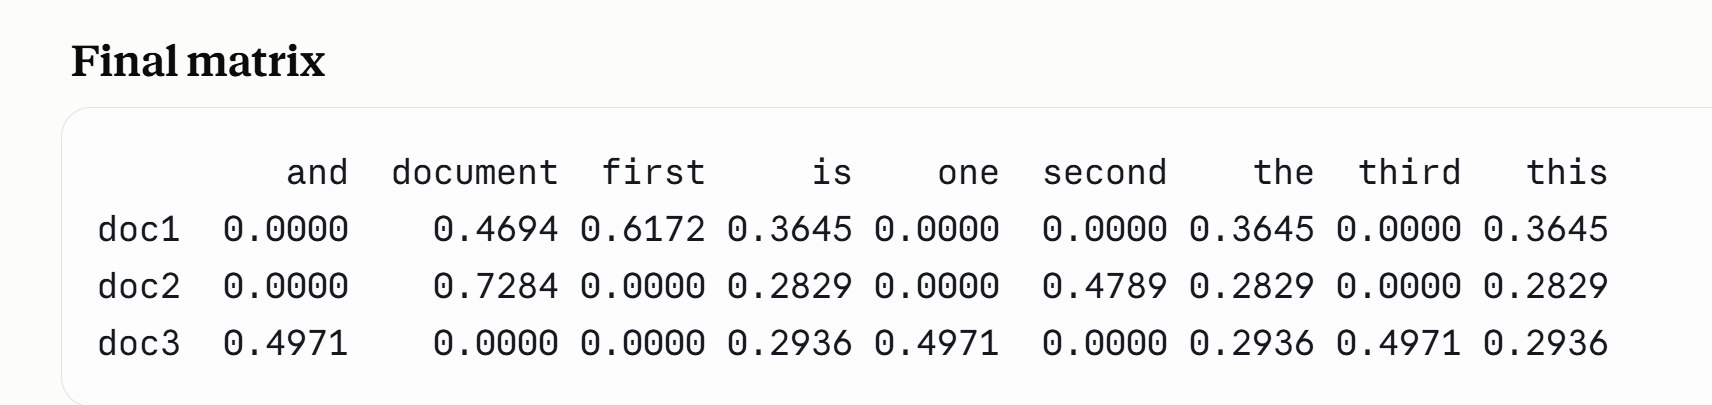

In [39]:
X.toarray()

array([[0.        , 0.46941728, 0.61722732, 0.3645444 , 0.        ,
        0.        , 0.3645444 , 0.        , 0.3645444 ],
       [0.        , 0.7284449 , 0.        , 0.28285122, 0.        ,
        0.47890875, 0.28285122, 0.        , 0.28285122],
       [0.49711994, 0.        , 0.        , 0.29360705, 0.49711994,
        0.        , 0.29360705, 0.49711994, 0.29360705]])

In [40]:
from sklearn.feature_extraction.text import TfidfVectorizer

corpus = [
    "this is the first document",
    "this document is the second document",
    "and this is the third one",
]

vectorizer = TfidfVectorizer(max_df=0.9)
X = vectorizer.fit_transform(corpus)

print(vectorizer.get_feature_names_out())
print(X.toarray())

['and' 'document' 'first' 'one' 'second' 'third']
[[0.         0.60534851 0.79596054 0.         0.         0.        ]
 [0.         0.83559154 0.         0.         0.54935123 0.        ]
 [0.57735027 0.         0.         0.57735027 0.         0.57735027]]


In [41]:
def build_pipeline(max_features: int, C: float, ngram_max: int) -> Pipeline:
    return Pipeline(
        [
            ("tfidf", TfidfVectorizer(
                max_features=max_features,
                min_df=2,
                max_df=0.9,
                sublinear_tf=True,
                stop_words="english")
            ),
            (
                "clf", LogisticRegression(C=C, max_iter=1000, class_weight="balanced")
            )
        ]
    )

In [42]:
pipeline = build_pipeline(10, 1.0, 3)
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",'english'
,"max_df max_df: float or int, default=1.0When building the vocabulary ignore terms that have a documentfrequency strictly higher than the given threshold (corpus-specificstop words).If float in range [0.0, 1.0], the parameter represents a proportion ofdocuments, integer absolute counts.This parameter is ignored if vocabulary is not None.",0.9
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",10
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expe

In [46]:
pipeline.named_steps['clf']

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to

In [47]:
def score(model: Pipeline, X, y) -> dict:
    preds = model.predict(X)
    return {
        "accuracy": round(accuracy_score(y, preds), 3),
        "precision": round(precision_score(y, preds, zero_division=0), 3),
        "recall": round(recall_score(y, preds, zero_division=0), 3),
        "f1": round(f1_score(y, preds, zero_division=0), 3)
    }

def top_words(model: Pipeline, n: int = 15) -> dict:
    vocab = model.named_steps["tfidf"].get_feature_names_out()
    coefs = model.named_steps['clf'].coef_[0]
    order = coefs.argsort()
    return {
        "fake": [str(vocab[i]) for i in order[::-1][:n]],
        "real": [str(vocab[i]) for i in order[:n]]
    }

In [48]:
df.head()

,content,label
0,"as u.s. budget fight looms, republicans flip t...",true
1,u.s. military to accept transgender recruits o...,true
2,senior u.s. republican senator: 'let mr. muell...,true
3,fbi russia probe helped by australian diplomat...,true
4,trump wants postal service to charge 'much mor...,true


In [50]:
import warnings
warnings.filterwarnings("ignore")

In [55]:
df['label'] = df['label'].map(func=lambda x: 0 if x == "true" else 1)

In [56]:
df['label'].value_counts()

label
0    21195
1    17900
Name: count, dtype: int64

In [57]:
df.head()

,content,label
0,"as u.s. budget fight looms, republicans flip t...",0
1,u.s. military to accept transgender recruits o...,0
2,senior u.s. republican senator: 'let mr. muell...,0
3,fbi russia probe helped by australian diplomat...,0
4,trump wants postal service to charge 'much mor...,0


In [58]:
def split(df: pd.DataFrame):
    train, temp = train_test_split(df, test_size=0.3, stratify=df['label'], random_state=42)
    val, test = train_test_split(temp, test_size=0.5, stratify=temp["label"], random_state=42)

    return train, val, test

In [59]:
train, val, test = split(df)

In [60]:
train.shape

(27366, 2)

In [61]:
val.shape

(5864, 2)

In [62]:
test.shape

(5865, 2)

In [63]:
import json
from datetime import datetime, timezone
from pathlib import Path

import joblib

try:
    import mlflow
    import mlflow.sklearn
    MLFLOW_AVAILABLE = True
except ImportError:
    MLFLOW_AVAILABLE = False

print("MLflow available:", MLFLOW_AVAILABLE)

MLflow available: True


In [64]:
EXPERIMENT_NAME = "fake-news-tfidf"   # was args.experiment
model_dir

'C:\\Users\\user\\Documents\\AgenticAI\\fake-news-detector\\fake-news-detector\\models'

In [65]:
params = {"max_features": 20000, "C": 1.0, "ngram_max": 2}

model = build_pipeline(**params)
model.fit(train["content"], train["label"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",'english'
,"max_df max_df: float or int, default=1.0When building the vocabulary ignore terms that have a documentfrequency strictly higher than the given threshold (corpus-specificstop words).If float in range [0.0, 1.0], the parameter represents a proportion ofdocuments, integer absolute counts.This parameter is ignored if vocabulary is not None.",0.9
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",20000
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True


In [66]:
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, precision_score, recall_score,
)

In [67]:
train_metrics = score(model, train["content"], train["label"])
val_metrics = score(model, val["content"], val["label"])

print("Train:     ", train_metrics)
print("Validation:", val_metrics)

val_pred = model.predict(val["content"])
print(classification_report(val["label"], val_pred, target_names=["real (0)", "fake (1)"]))
print(confusion_matrix(val["label"], val_pred))

Train:      {'accuracy': 0.991, 'precision': 0.993, 'recall': 0.987, 'f1': 0.99}
Validation: {'accuracy': 0.982, 'precision': 0.985, 'recall': 0.976, 'f1': 0.98}
              precision    recall  f1-score   support

    real (0)       0.98      0.99      0.98      3179
    fake (1)       0.98      0.98      0.98      2685

    accuracy                           0.98      5864
   macro avg       0.98      0.98      0.98      5864
weighted avg       0.98      0.98      0.98      5864

[[3139   40]
 [  65 2620]]


In [68]:
words = top_words(model)
print("Words pointing to FAKE:", words["fake"])
print("Words pointing to REAL:", words["real"])

Words pointing to FAKE: ['video', 'image', 'featured', 'just', 'read', 'gop', 'getty', 'watch', 'america', 'obama', 'images', 'breaking', 'hillary', 'like', 'mr']
Words pointing to REAL: ['said', 'wednesday', 'tuesday', 'thursday', 'republican', 'friday', 'monday', 'nov', 'minister', 'presidential', 'spokesman', 'democratic', 'reporters', 'told', 'statement']


In [69]:
new_articles = [
    "Scientists confirm the new vaccine passed all clinical trials.",
    "SHOCKING: celebrity reveals the government is hiding aliens!!!",
]

preds = model.predict(new_articles)
probs = model.predict_proba(new_articles)[:, 1]   # probability of label 1 (fake)

for text, p, prob in zip(new_articles, preds, probs):
    print(f"{'FAKE' if p == 1 else 'REAL'}  ({prob:.2%} fake)  {text[:60]}")

FAKE  (57.17% fake)  Scientists confirm the new vaccine passed all clinical trial
FAKE  (88.65% fake)  SHOCKING: celebrity reveals the government is hiding aliens!


In [70]:
test_metrics = score(model, test["content"], test["label"])
print("Test:", test_metrics)

Test: {'accuracy': 0.982, 'precision': 0.987, 'recall': 0.973, 'f1': 0.98}


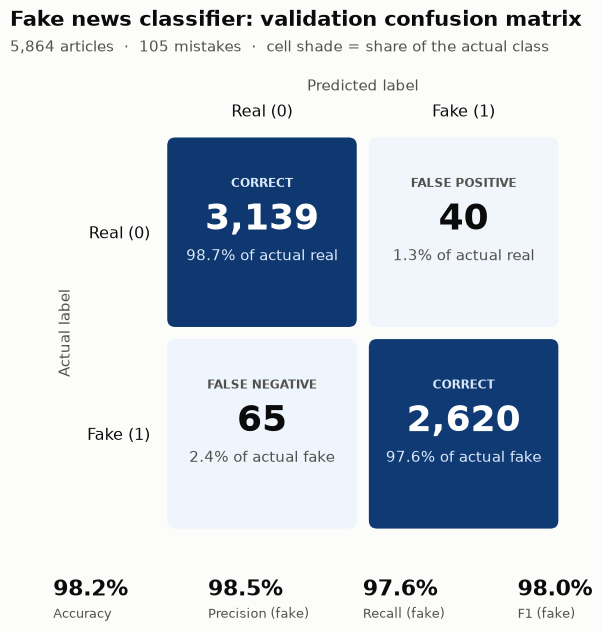

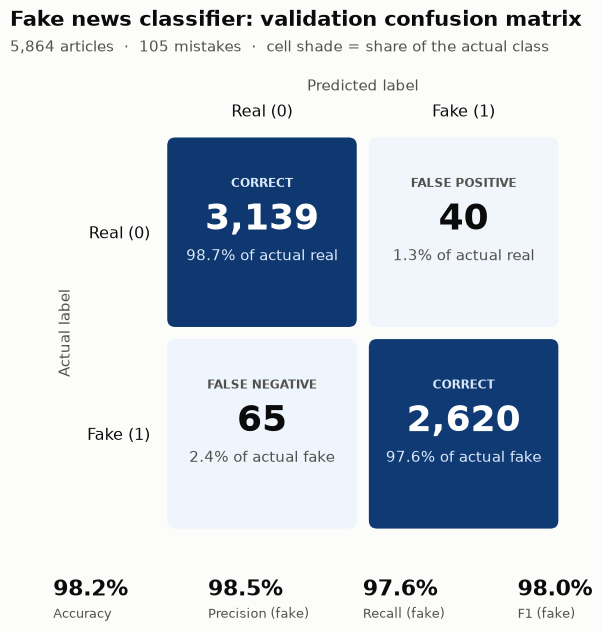

In [71]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch
from sklearn.metrics import confusion_matrix


def plot_confusion_matrix(y_true, y_pred, title="Fake news classifier: validation confusion matrix",
                          class_names=("Real (0)", "Fake (1)"), save_path=None):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    total = cm.sum()
    row_pct = cm / cm.sum(axis=1, keepdims=True)
    accuracy = np.trace(cm) / total
    precision = cm[1, 1] / cm[:, 1].sum()
    recall = cm[1, 1] / cm[1].sum()
    f1 = 2 * precision * recall / (precision + recall)

    # Colours
    SURFACE, INK, INK_2 = "#fcfcfb", "#0b0b0b", "#52514e"
    blues = LinearSegmentedColormap.from_list(
        "blues", ["#f3f7fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
    )

    fig, ax = plt.subplots(figsize=(7.2, 6.4), facecolor=SURFACE)
    ax.set_facecolor(SURFACE)

    # Cells
    gap = 0.03
    for i in range(2):
        for j in range(2):
            pct = row_pct[i, j]
            ax.add_patch(FancyBboxPatch(
                (j + gap, i + gap), 1 - 2 * gap, 1 - 2 * gap,
                boxstyle="round,pad=0,rounding_size=0.04",
                facecolor=blues(pct), edgecolor="none",
            ))
            dark_cell = pct > 0.5
            main_color = "white" if dark_cell else INK
            sub_color = "#dbe8fa" if dark_cell else INK_2

            kind = ("Correct" if i == j else
                    "False positive" if (i, j) == (0, 1) else "False negative")
            actual = class_names[i].split()[0].lower()

            ax.text(j + 0.5, i + 0.26, kind.upper(), ha="center", va="center",
                    fontsize=8.5, fontweight="bold", color=sub_color)
            ax.text(j + 0.5, i + 0.44, f"{cm[i, j]:,}", ha="center", va="center",
                    fontsize=26, fontweight="bold", color=main_color)
            ax.text(j + 0.5, i + 0.62, f"{pct:.1%} of actual {actual}", ha="center",
                    va="center", fontsize=10.5, color=sub_color)

    # Axes
    ax.set_xlim(0, 2)
    ax.set_ylim(2, 0)
    ax.set_aspect("equal")
    ax.set_xticks([0.5, 1.5], class_names, color=INK, fontsize=11.5)
    ax.set_yticks([0.5, 1.5], class_names, color=INK, fontsize=11.5)
    ax.xaxis.set_label_position("top")
    ax.xaxis.tick_top()
    ax.set_xlabel("Predicted label", color=INK_2, fontsize=11, labelpad=10)
    ax.set_ylabel("Actual label", color=INK_2, fontsize=11, labelpad=10)
    ax.tick_params(length=0, pad=8)
    for spine in ax.spines.values():
        spine.set_visible(False)

    # Title and subtitle
    fig.text(0.07, 0.965, title, fontsize=15, fontweight="bold", color=INK)
    fig.text(0.07, 0.925,
             f"{total:,} articles  ·  {cm[0, 1] + cm[1, 0]:,} mistakes  ·  "
             "cell shade = share of the actual class",
             fontsize=10.5, color=INK_2)

    # Metrics row
    metrics = [("Accuracy", accuracy), ("Precision (fake)", precision),
               ("Recall (fake)", recall), ("F1 (fake)", f1)]
    for k, (name, value) in enumerate(metrics):
        x = 0.13 + k * 0.215
        fig.text(x, 0.075, f"{value:.1%}", fontsize=16, fontweight="bold", color=INK)
        fig.text(x, 0.04, name, fontsize=9.5, color=INK_2)

    fig.subplots_adjust(left=0.17, right=0.95, top=0.80, bottom=0.17)

    if save_path:
        fig.savefig(save_path, dpi=200, facecolor=SURFACE, bbox_inches="tight")
    plt.show()
    return fig


val_pred = model.predict(val["content"])
plot_confusion_matrix(val["label"], val_pred)

In [ ]:
import mlflow
import mlflow.sklearn

mlflow.set_experiment("fake-news-tfidf")

with mlflow.start_run() as run:
    # 1. Settings
    mlflow.log_params({**params, "model_type": "tfidf+logreg"})

    # 2. Scores
    mlflow.log_metrics({f"train_{k}": v for k, v in train_metrics.items()})
    mlflow.log_metrics({f"val_{k}": v for k, v in val_metrics.items()})

    # 3. Files
    fig = plot_confusion_matrix(val["label"], model.predict(val["content"]))
    mlflow.log_figure(fig, "confusion_matrix.png")
    mlflow.log_artifact(str(model_dir / "metadata.json"))

    # 4. The model
    try:
        mlflow.sklearn.log_model(model, name="model")           # MLflow 3.x
    except TypeError:
        mlflow.sklearn.log_model(model, artifact_path="model")  # MLflow 2.x

print("Run ID:", run.info.run_id)